# experiment_2 — 학습률 스케줄 고정(SGD) + batch 크기 비교

| 항목 | 내용 |
| --- | --- |
| 목적 | 팀장 지시: lr을 설계값대로(0.001 → 0.0001) 천천히 줄이고, batch를 4씩 키워 비교, epoch는 수백 |
| 고정 | `optimizer=SGD` (auto는 lr0를 무시하고 AdamW로 바꿔서 지정), `lr0=0.001`, `lrf=0.1`(끝 lr 0.0001), warmup 3 epoch(bias 0.01 → 0.001, momentum 0.8 → 0.937), `epochs=300`, `patience=100` |
| 비교 | `BATCHES = [8, 12, 16, 20]` — batch마다 같은 설정으로 처음부터 학습 |
| 스케줄 | 이번 실행 **linear** (`COS_LR=False`). 다음 실행은 0번 셀에서 `COS_LR=True`만 바꿔 **cosine** |
| 데이터 | 합성 `turtle_ninja_split_s0_shape4` (train 400 / val 50 / test 50, 4클래스) + 실물 `real_wide_test` (따로 평가) |
| 모델 선택 | batch마다 val **mAP50** 최고 epoch → `b<batch>/weights/best_map50.pt`, 평가·추론 모두 이 파일 |
| 기록 | 셀 출력 + `yolo/train/results/<RUN_ID>/` (git 제외): `run.log`, batch별 폴더, `runs.json`, `comparison.csv/png`, `summary.md` |

**실행 (오래 걸려요: batch 하나에 약 1시간 × 4)** — 끝까지 한 번에 돌리고 출력까지 저장:
```bash
cd ~/바탕화면/git/Project2_Turtle_Ninja/yolo/train
~/pa-course/.venv-yolo/bin/jupyter nbconvert --to notebook --execute --inplace \
    --ExecutePreprocessor.timeout=-1 experiment_2.ipynb
```
- GPU 메모리가 부족한 batch(OOM)는 기록만 하고 다음 batch로 넘어가요. 1280에서 batch 8이 5.6 GB였어서 16 이상은 OOM일 수 있어요.
- batch 하나 끝날 때마다 `runs.json`에 저장돼서, 중간에 멈춰도 끝난 결과는 남아요.
- **실물 점수를 믿으려면 실물 라벨이 4클래스 번호(0 qr · 1 puck_cyl · 2 puck_box · 3 signal_tower)여야 해요.**

**셀 순서**: 0 설정 → 1 로그 → 2 환경 → 3 클래스 → 4 split → 4-R 실물셋 → 5 통계 → 6 사전학습 가중치 → 7 batch별 학습·평가 → 8 비교 → 9 요약

## 0. 설정 — 실험마다 여기만 바꾸기

In [1]:
from pathlib import Path
from datetime import datetime

EXP_NAME = "experiment_2"
RUN_ID = f"{EXP_NAME}_{datetime.now():%Y%m%d_%H%M%S}"   # 다시 돌려도 이전 기록을 덮어쓰지 않음

HOME = Path.home()
REPO = HOME / "바탕화면/git/Project2_Turtle_Ninja"
SRC_DATASET = REPO / "yolo/datasets/turtle_ninja_shape"      # convert_to_yolo.py --classes shape 결과 (모양 구분 6클래스)
SRC_SPLITS = ["train"]                                         # 여기 있는 사진을 전부 모아서 다시 나눔
SPLIT_SEED = 0
SPLIT_RATIO = {"train": 0.8, "val": 0.1, "test": 0.1}
SPLIT_DATASET = REPO / f"yolo/datasets/turtle_ninja_split_s{SPLIT_SEED}_shape4"   # git 제외 폴더. 4클래스(모양 구분, 누운 퍽 포함)

WEIGHTS_DIR = REPO / "yolo/models"                             # *.pt 는 git 제외
PRETRAINED = WEIGHTS_DIR / "yolo26n.pt"

REAL_TEST_DIR = REPO / "yolo/datasets/real_wide_test"         # 실제 광각 사진 (images/, labels/)
CONF = 0.5                                                     # 예측 표시 기준 = planning 기준 (0.5 미만은 버림)

PROJECT = REPO / "yolo/train/results"                          # 이 노트북 폴더 안. 폴더 전체가 git 제외됨
EXP_DIR = PROJECT / RUN_ID

BATCHES = [8, 12, 16, 20]      # 4씩 키워서 비교 (OOM 나면 그 batch만 기록하고 넘어감)
COS_LR = False                 # False = linear (이번), True = cosine (다음 실행)
SCHEDULE = "cosine" if COS_LR else "linear"
EXP_NAME = f"{EXP_NAME}_{SCHEDULE}"
RUN_ID = f"{EXP_NAME}_{datetime.now():%Y%m%d_%H%M%S}"
EXP_DIR = PROJECT / RUN_ID

TRAIN_CFG = dict(
    epochs=300,
    patience=100,         # 100 epoch 동안 나아지지 않으면 멈춤 (20이면 수백 epoch 전에 멈춤)
    imgsz=1280,           # 광각 원본 1280x720
    device=0,
    workers=8,
    seed=0,
    deterministic=True,
    # --- 학습률 (팀장 지시) ---
    optimizer="SGD",      # auto면 lr0를 무시하고 AdamW + 자동 lr로 바뀜 → 반드시 SGD 지정
    lr0=0.001,            # 시작 lr
    lrf=0.1,              # 끝 lr = lr0 × lrf = 0.0001
    cos_lr=COS_LR,        # False: linear, True: cosine
    momentum=0.937,
    # --- warmup ---
    warmup_epochs=3,      # 0 → lr0 (최소 100 step 보장이라 batch가 크면 4~5 epoch)
    warmup_bias_lr=0.01,  # bias lr: 0.01 → 0.001 (lr0의 10배에서 시작, 기본 설계 비율)
    warmup_momentum=0.8,  # momentum: 0.8 → 0.937
    # --- 그 외 (experiment_1과 동일) ---
    close_mosaic=10,
    hsv_h=0.015,
    pretrained=True,
    plots=True,
    save=True,
    verbose=True,
)
print("RUN_ID     :", RUN_ID)
print("BATCHES    :", BATCHES, "| schedule:", SCHEDULE)
print("LR         :", TRAIN_CFG["optimizer"], "lr0", TRAIN_CFG["lr0"], "→ 끝", TRAIN_CFG["lr0"] * TRAIN_CFG["lrf"])
print("EXP_DIR    :", EXP_DIR)
print("SRC        :", SRC_DATASET, SRC_SPLITS)
print("SPLIT      :", SPLIT_DATASET, SPLIT_RATIO, "seed", SPLIT_SEED)
print("PRETRAINED :", PRETRAINED)
print("REAL TEST  :", REAL_TEST_DIR)
print("CONF       :", CONF)

RUN_ID     : experiment_2_linear_20261023_164149
BATCHES    : [8, 12, 16, 20] | schedule: linear
LR         : SGD lr0 0.001 → 끝 0.0001
EXP_DIR    : /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_2_linear_20261023_164149
SRC        : /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/turtle_ninja_shape ['train']
SPLIT      : /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/turtle_ninja_split_s0_shape4 {'train': 0.8, 'val': 0.1, 'test': 0.1} seed 0
PRETRAINED : /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/models/yolo26n.pt
REAL TEST  : /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/real_wide_test
CONF       : 0.5


## 1. 로그 시작 — 이 셀 이후의 모든 출력이 `run.log`에도 저장돼요

In [2]:
import sys, json, logging

PROJECT.mkdir(parents=True, exist_ok=True)
gi = PROJECT / ".gitignore"
if not gi.exists():
    gi.write_text("# 실험 결과(가중치·이미지·로그)는 커밋하지 않음\n*\n", encoding="utf-8")
EXP_DIR.mkdir(parents=True, exist_ok=False)
LOG_PATH = EXP_DIR / "run.log"

class Tee:
    """화면 출력과 run.log에 동시에 쓰기 (노트북 출력은 그대로 남음)."""
    def __init__(self, stream, path):
        self.stream, self.file = stream, open(path, "a", encoding="utf-8", buffering=1)
    def write(self, s):
        self.stream.write(s)
        self.file.write(s)
        return len(s)
    def flush(self):
        self.stream.flush(); self.file.flush()
    def __getattr__(self, name):
        return getattr(self.stream, name)

if not isinstance(sys.stdout, Tee):
    sys.stdout = Tee(sys.stdout, LOG_PATH)
    sys.stderr = Tee(sys.stderr, LOG_PATH)

def save_json(name, obj):
    p = EXP_DIR / name
    p.write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    print("saved", p)

save_json("config.json", dict(RUN_ID=RUN_ID, SRC_DATASET=SRC_DATASET, SRC_SPLITS=SRC_SPLITS,
                              SPLIT_SEED=SPLIT_SEED, SPLIT_RATIO=SPLIT_RATIO,
                              SPLIT_DATASET=SPLIT_DATASET, PRETRAINED=PRETRAINED, TRAIN_CFG=TRAIN_CFG,
                              REAL_TEST_DIR=REAL_TEST_DIR, CONF=CONF, model_selection="max val mAP50",
                              BATCHES=BATCHES, SCHEDULE=SCHEDULE))
print(f"[{datetime.now():%F %T}] 로그 시작 → {LOG_PATH}")

saved /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_2_linear_20261023_164149/config.json
[2026-10-23 16:41:49] 로그 시작 → /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_2_linear_20261023_164149/run.log


## 2. 환경 기록 — 버전·GPU·git 상태

In [3]:
import platform, subprocess
import torch, ultralytics

def git(*args):
    try:
        return subprocess.run(["git", "-C", str(REPO), *args], capture_output=True, text=True).stdout.strip()
    except Exception as e:
        return f"error: {e}"

env = dict(
    time=datetime.now().isoformat(timespec="seconds"),
    python=sys.version.split()[0],
    platform=platform.platform(),
    torch=torch.__version__,
    cuda_available=torch.cuda.is_available(),
    cuda=torch.version.cuda,
    gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    ultralytics=ultralytics.__version__,
    git_branch=git("rev-parse", "--abbrev-ref", "HEAD"),
    git_commit=git("rev-parse", "--short", "HEAD"),
    git_dirty_files=len([l for l in git("status", "--porcelain").splitlines() if l.strip()]),
)
for k, v in env.items():
    print(f"{k:16s} {v}")
save_json("env.json", env)
assert env["cuda_available"], "GPU가 안 잡혀요. 커널이 .venv-yolo인지 확인하세요."

time             2026-10-23T16:41:52
python           3.12.3
platform         Linux-7.0.0-38-generic-x86_64-with-glibc2.39
torch            2.11.0+cu128
cuda_available   True
cuda             12.8
gpu              NVIDIA GeForce RTX 5060 Laptop GPU
ultralytics      8.4.183
git_branch       feat/camera_calib
git_commit       e6197f1
git_dirty_files  1
saved /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_2_linear_20261023_164149/env.json


## 3. 클래스 정의 — 학습 전에 눈으로 확인

**4클래스 (퍽 모양 구분)**: 원기둥 퍽 `puck_cyl`과 직육면체 퍽 `puck_box`를 나눠요. 누운 퍽은 따로 두지 않고 **모양 클래스에 포함**해요. planning `shape` 필드(`cylinder` / `box`)와 1:1로 맞아요.

원본 데이터는 `convert_to_yolo.py --classes shape`로 변환한 6클래스(`qr, puck_cyl, puck_box, puck_cyl_fallen, puck_box_fallen, signal_tower`)예요. 4번 셀에서 split 폴더를 만들 때 라벨 번호를 아래 `SRC_TO_NEW` 표대로 바꿔 써요. 원본 파일은 건드리지 않아요. 원본 `data.yaml`의 이름이 예상과 다르면 이 셀에서 멈춰요.

원본이 없으면 먼저 터미널에서 (feat/camera_calib 브랜치, 레포 루트):
```bash
python3 yolo/dataset_gen/convert_to_yolo.py yolo/datasets/sim_raw/wide_001 yolo/datasets/turtle_ninja_shape \
    --split train --prefix wide_001 --classes shape
```

In [4]:
import yaml

CLASSES = [
    # id, 이름,          무엇인지,                                    sim 원본 라벨 (convert_to_yolo.py)
    (0, "qr",           "벽에 붙은 QR/바코드 판 (내용은 YOLO가 아니라 디코더가 읽음)", "qr"),
    (1, "puck_cyl",     "원기둥 퍽 Ø30x60mm. 서 있든 누워 있든 (색은 후처리 HSV) → planning shape=cylinder",
                        "puck_cyl, puck_cyl_fallen"),
    (2, "puck_box",     "직육면체 퍽 30x30x60mm. 서 있든 누워 있든 (색은 후처리 HSV) → planning shape=box",
                        "puck_box, puck_box_fallen"),
    (3, "signal_tower", "신호등 기둥 전체 (점등 색은 후처리로 판별)",                 "signal_tower"),
]
NOT_LABELED = {"wall_joint": "파란 벽 연결 부품. 라벨 없이 배경(hard negative)으로 학습"}

NAMES = {i: n for i, n, _, _ in CLASSES}
print(f"{'id':>2}  {'name':14s} {'sim 라벨':34s} 설명")
print("-" * 110)
for i, n, desc, src in CLASSES:
    print(f"{i:>2}  {n:14s} {src:34s} {desc}")
for n, desc in NOT_LABELED.items():
    print(f" -  {n:14s} {'(라벨 없음)':34s} {desc}")

src_yaml = yaml.safe_load((SRC_DATASET / "data.yaml").read_text(encoding="utf-8"))
src_names = {int(k): v for k, v in src_yaml["names"].items()} if isinstance(src_yaml["names"], dict) \
    else dict(enumerate(src_yaml["names"]))
print("\n원본 data.yaml names:", src_names)
EXPECTED_SRC = {0: "qr", 1: "puck_cyl", 2: "puck_box", 3: "puck_cyl_fallen", 4: "puck_box_fallen", 5: "signal_tower"}
assert src_names == EXPECTED_SRC, f"원본 data.yaml 클래스가 예상과 달라요: {src_names}"
MERGE = {"qr": "qr", "puck_cyl": "puck_cyl", "puck_box": "puck_box",                       # 원본 이름 → 새 이름
         "puck_cyl_fallen": "puck_cyl", "puck_box_fallen": "puck_box", "signal_tower": "signal_tower"}
NEW_ID = {n: i for i, n in NAMES.items()}
SRC_TO_NEW = {i: NEW_ID[MERGE[n]] for i, n in src_names.items()}
print("라벨 번호 변환 SRC_TO_NEW:", ", ".join(f"{i}({src_names[i]}) → {j}({NAMES[j]})" for i, j in SRC_TO_NEW.items()))
print("✔ 클래스 정의 확인")
save_json("classes.json", dict(classes=[dict(id=i, name=n, description=d, sim_labels=s) for i, n, d, s in CLASSES],
                               not_labeled=NOT_LABELED, source_names=src_names, src_to_new=SRC_TO_NEW))

id  name           sim 라벨                             설명
--------------------------------------------------------------------------------------------------------------
 0  qr             qr                                 벽에 붙은 QR/바코드 판 (내용은 YOLO가 아니라 디코더가 읽음)
 1  puck_cyl       puck_cyl, puck_cyl_fallen          원기둥 퍽 Ø30x60mm. 서 있든 누워 있든 (색은 후처리 HSV) → planning shape=cylinder
 2  puck_box       puck_box, puck_box_fallen          직육면체 퍽 30x30x60mm. 서 있든 누워 있든 (색은 후처리 HSV) → planning shape=box
 3  signal_tower   signal_tower                       신호등 기둥 전체 (점등 색은 후처리로 판별)
 -  wall_joint     (라벨 없음)                            파란 벽 연결 부품. 라벨 없이 배경(hard negative)으로 학습

원본 data.yaml names: {0: 'qr', 1: 'puck_cyl', 2: 'puck_box', 3: 'puck_cyl_fallen', 4: 'puck_box_fallen', 5: 'signal_tower'}
라벨 번호 변환 SRC_TO_NEW: 0(qr) → 0(qr), 1(puck_cyl) → 1(puck_cyl), 2(puck_box) → 2(puck_box), 3(puck_cyl_fallen) → 1(puck_cyl), 4(puck_box_fallen) → 2(puck_box), 5(signal_tower) → 3(signal_tower)
✔ 클래스 정의 확

## 4. train / val / test 나누기

- 원본 폴더의 사진을 모두 모아 `SPLIT_SEED`로 섞고 8:1:1로 나눠요. 같은 seed면 항상 같은 결과예요.
- 사진은 **심볼릭 링크**, 라벨은 4클래스 번호로 **바꿔서 새로 써요** → 새 폴더 `turtle_ninja_split_s0_shape4`.
- 폴더가 이미 있으면 새로 만들지 않고, 저장된 목록(`split_manifest.csv`)과 같은지 확인만 해요.
- **test는 학습·조기 종료에 전혀 쓰지 않고** 마지막 9번 셀에서 한 번만 평가해요.

In [5]:
import csv, random, os

def collect_pairs():
    pairs = []
    for s in SRC_SPLITS:
        for img in sorted((SRC_DATASET / "images" / s).glob("*.png")):
            lbl = SRC_DATASET / "labels" / s / (img.stem + ".txt")
            assert lbl.exists(), f"라벨 없음: {lbl}"
            pairs.append((img, lbl))
    return pairs

pairs = collect_pairs()
print("원본 사진 수:", len(pairs), {s: len(list((SRC_DATASET / 'images' / s).glob('*.png'))) for s in SRC_SPLITS})

order = list(range(len(pairs)))
random.Random(SPLIT_SEED).shuffle(order)
n = len(order)
n_train = round(n * SPLIT_RATIO["train"]); n_val = round(n * SPLIT_RATIO["val"])
assign = {}
for k, idx in enumerate(order):
    assign[idx] = "train" if k < n_train else "val" if k < n_train + n_val else "test"

manifest = [(assign[i], pairs[i][0].name, str(pairs[i][0])) for i in range(n)]
manifest.sort()
manifest_path = SPLIT_DATASET / "split_manifest.csv"

if SPLIT_DATASET.exists():
    with open(manifest_path, encoding="utf-8") as f:
        old = [tuple(r) for r in csv.reader(f)][1:]
    assert old == [tuple(m) for m in manifest], "기존 split 폴더와 목록이 달라요. SPLIT_SEED나 원본이 바뀌었는지 확인하세요."
    print("기존 split 폴더 재사용:", SPLIT_DATASET)
else:
    for i, (img, lbl) in enumerate(pairs):
        s = assign[i]
        (SPLIT_DATASET / "images" / s).mkdir(parents=True, exist_ok=True)
        (SPLIT_DATASET / "labels" / s).mkdir(parents=True, exist_ok=True)
        os.symlink(img.resolve(), SPLIT_DATASET / "images" / s / img.name)
        out = []
        for l in lbl.read_text().splitlines():
            if l.strip():
                c, *rest = l.split()
                out.append(" ".join([str(SRC_TO_NEW[int(c)]), *rest]))
        (SPLIT_DATASET / "labels" / s / lbl.name).write_text("\n".join(out) + ("\n" if out else ""))
    with open(manifest_path, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f); w.writerow(["split", "file", "source"]); w.writerows(manifest)
    print("새 split 폴더 생성:", SPLIT_DATASET)

DATA_YAML = SPLIT_DATASET / "data.yaml"
DATA_YAML.write_text(yaml.safe_dump(dict(path=str(SPLIT_DATASET), train="images/train", val="images/val",
                                         test="images/test", names=NAMES), allow_unicode=True, sort_keys=False),
                     encoding="utf-8")
print(DATA_YAML.read_text(encoding="utf-8"))

import shutil
shutil.copy2(manifest_path, EXP_DIR / "split_manifest.csv")
shutil.copy2(DATA_YAML, EXP_DIR / "data.yaml")
for s in ("train", "val", "test"):
    print(f"{s:5s}: {sum(1 for v in assign.values() if v == s)}장")

원본 사진 수: 500 {'train': 500}
기존 split 폴더 재사용: /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/turtle_ninja_split_s0_shape4
path: /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/turtle_ninja_split_s0_shape4
train: images/train
val: images/val
test: images/test
names:
  0: qr
  1: puck_cyl
  2: puck_box
  3: signal_tower

train: 400장
val  : 50장
test : 50장


## 4-R. 실물 광각 테스트셋 확인 — 합성 데이터와 완전히 별도

- 학습·검증에는 전혀 쓰지 않고 9-R·10-R에서만 써요.
- 라벨(`labels/*.txt`)이 있는 사진만 mAP에 들어가요. 빈 .txt = 물체 없음(배경) 사진.
- 해상도가 1280x720이 아니거나 라벨 클래스 번호가 범위를 벗어나면 경고해요.

In [6]:
from PIL import Image
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp")
real_imgs = sorted(p for p in (REAL_TEST_DIR / "images").glob("*") if p.suffix.lower() in IMG_EXT) \
    if (REAL_TEST_DIR / "images").exists() else []
real_labeled, real_unlabeled = [], []
real_stats = dict(images=len(real_imgs), labeled=0, unlabeled=0, background=0, boxes=0,
                  per_class={NAMES[c]: 0 for c in NAMES}, bad_size=[], bad_class=[])
for p in real_imgs:
    lbl = REAL_TEST_DIR / "labels" / (p.stem + ".txt")
    with Image.open(p) as im:
        w, h = im.size
    if (w, h) != (1280, 720):
        real_stats["bad_size"].append(f"{p.name} {w}x{h}")
    if not lbl.exists():
        real_unlabeled.append(p); continue
    real_labeled.append(p)
    rows = [l.split() for l in lbl.read_text().splitlines() if l.strip()]
    real_stats["background"] += not rows
    for r in rows:
        c = int(r[0])
        if c not in NAMES:
            real_stats["bad_class"].append(f"{lbl.name}: {c}"); continue
        real_stats["per_class"][NAMES[c]] += 1; real_stats["boxes"] += 1
real_stats["labeled"], real_stats["unlabeled"] = len(real_labeled), len(real_unlabeled)
HAS_REAL = len(real_imgs) > 0
HAS_REAL_LABELS = len(real_labeled) > 0

print(f"실물 사진 {real_stats['images']}장 | 라벨 있음 {real_stats['labeled']} (배경 {real_stats['background']}) "
      f"| 라벨 없음 {real_stats['unlabeled']} | 상자 {real_stats['boxes']}")
print("클래스별 상자:", real_stats["per_class"])
if real_stats["bad_size"]:  print("⚠ 1280x720 아님:", real_stats["bad_size"])
if real_stats["bad_class"]: print("⚠ 없는 클래스 번호:", real_stats["bad_class"])
if not HAS_REAL:
    print(f"⚠ 실물 사진이 없어요 → 9-R·10-R은 건너뜀 ({REAL_TEST_DIR / 'images'})")
elif not HAS_REAL_LABELS:
    print("⚠ 라벨이 하나도 없어요 → 9-R(mAP)은 건너뛰고 10-R에서 예측 결과만 보여줌")

# mAP 계산용: 라벨 있는 사진만 링크로 모은 별도 폴더 + data_real.yaml (합성 data.yaml과 분리)
REAL_EVAL_DIR = EXP_DIR / "real_test_set"
if HAS_REAL_LABELS:
    for kind in ("images", "labels"):
        (REAL_EVAL_DIR / kind / "test").mkdir(parents=True, exist_ok=True)
    for p in real_labeled:
        os.symlink(p.resolve(), REAL_EVAL_DIR / "images" / "test" / p.name)
        os.symlink((REAL_TEST_DIR / "labels" / (p.stem + ".txt")).resolve(), REAL_EVAL_DIR / "labels" / "test" / (p.stem + ".txt"))
    DATA_REAL_YAML = EXP_DIR / "data_real.yaml"
    DATA_REAL_YAML.write_text(yaml.safe_dump(dict(path=str(REAL_EVAL_DIR), train="images/test", val="images/test",
                                                  test="images/test", names=NAMES), allow_unicode=True, sort_keys=False),
                              encoding="utf-8")
    print(DATA_REAL_YAML.read_text(encoding="utf-8"))
save_json("real_test_stats.json", dict(real_stats, labeled_files=[p.name for p in real_labeled],
                                       unlabeled_files=[p.name for p in real_unlabeled]))

실물 사진 49장 | 라벨 있음 49 (배경 2) | 라벨 없음 0 | 상자 94
클래스별 상자: {'qr': 23, 'puck_cyl': 68, 'puck_box': 3, 'signal_tower': 0}
path: /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_2_linear_20261023_164149/real_test_set
train: images/test
val: images/test
test: images/test
names:
  0: qr
  1: puck_cyl
  2: puck_box
  3: signal_tower

saved /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_2_linear_20261023_164149/real_test_stats.json


## 5. 데이터 통계와 라벨 샘플 — split마다 클래스 수가 고르게 들어갔는지 확인

split     사진    빈사진     상자            qr      puck_cyl      puck_box  signal_tower
train    400      5   1102             0           457           475           170
val       50      0    132             0            41            66            25
test      50      0    149             0            68            58            23
saved /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_2_linear_20261023_164149/dataset_stats.json
⚠ train에 'qr' 상자가 0개 → 이 클래스는 train 지표가 안 나와요
⚠ val에 'qr' 상자가 0개 → 이 클래스는 val 지표가 안 나와요
⚠ test에 'qr' 상자가 0개 → 이 클래스는 test 지표가 안 나와요


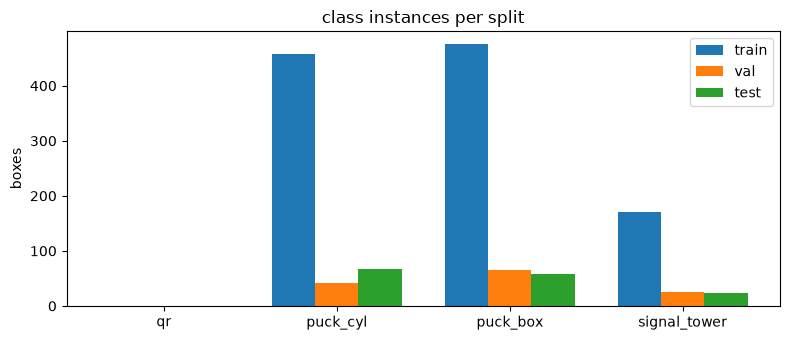

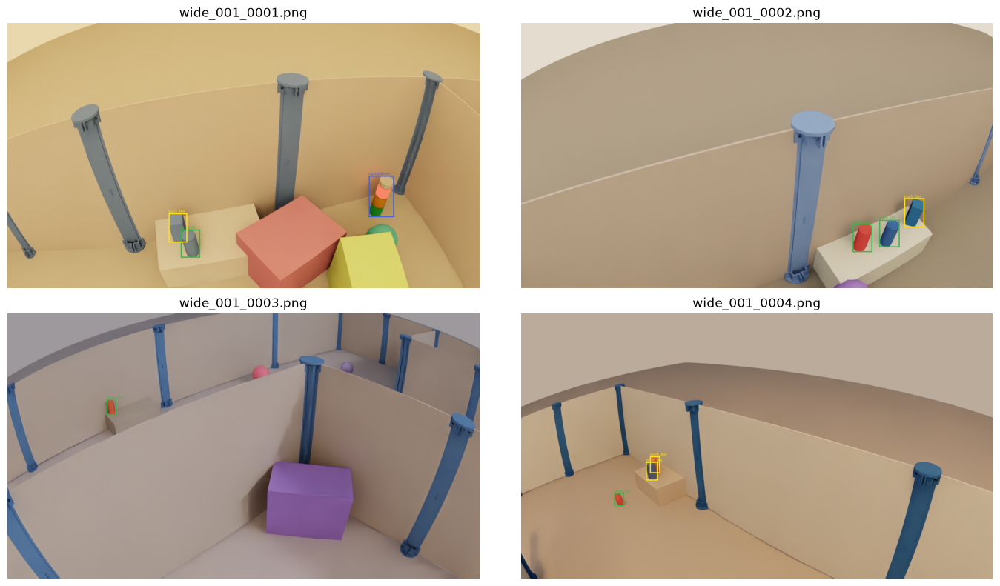

In [7]:
from collections import Counter
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

stats = {}
for s in ("train", "val", "test"):
    cnt, empty, n_img = Counter(), 0, 0
    for lbl in sorted((SPLIT_DATASET / "labels" / s).glob("*.txt")):
        rows = [l.split() for l in lbl.read_text().splitlines() if l.strip()]
        n_img += 1
        empty += not rows
        cnt.update(int(r[0]) for r in rows)
    stats[s] = dict(images=n_img, empty_images=empty, boxes=sum(cnt.values()),
                    per_class={NAMES[c]: cnt.get(c, 0) for c in NAMES})

print(f"{'split':6s} {'사진':>5s} {'빈사진':>6s} {'상자':>6s}  " + "  ".join(f"{NAMES[c]:>12s}" for c in NAMES))
for s, st in stats.items():
    print(f"{s:6s} {st['images']:5d} {st['empty_images']:6d} {st['boxes']:6d}  "
          + "  ".join(f"{st['per_class'][NAMES[c]]:12d}" for c in NAMES))
save_json("dataset_stats.json", stats)
for s, st in stats.items():
    for c in NAMES:
        if st["per_class"][NAMES[c]] == 0:
            print(f"⚠ {s}에 '{NAMES[c]}' 상자가 0개 → 이 클래스는 {s} 지표가 안 나와요")

fig, ax = plt.subplots(figsize=(8, 3.5))
w = 0.25
for k, s in enumerate(stats):
    ax.bar([c + (k - 1) * w for c in NAMES], [stats[s]["per_class"][NAMES[c]] for c in NAMES], w, label=s)
ax.set_xticks(list(NAMES)); ax.set_xticklabels(list(NAMES.values())); ax.set_ylabel("boxes"); ax.legend()
ax.set_title("class instances per split"); fig.tight_layout()
fig.savefig(EXP_DIR / "class_counts.png", dpi=120); plt.show()

COLORS = ["#e6194b", "#3cb44b", "#ffe119", "#4363d8"]
def draw(img_path, lbl_path):
    im = Image.open(img_path).convert("RGB"); W, H = im.size; d = ImageDraw.Draw(im)
    for l in lbl_path.read_text().splitlines():
        if not l.strip(): continue
        c, cx, cy, bw, bh = int(l.split()[0]), *map(float, l.split()[1:])
        x0, y0, x1, y1 = (cx - bw / 2) * W, (cy - bh / 2) * H, (cx + bw / 2) * W, (cy + bh / 2) * H
        d.rectangle([x0, y0, x1, y1], outline=COLORS[c % 4], width=3)
        d.text((x0, max(0, y0 - 12)), NAMES[c], fill=COLORS[c % 4])
    return im

samples = sorted((SPLIT_DATASET / "images" / "train").glob("*.png"))[:4]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for a, p in zip(axes.flat, samples):
    a.imshow(draw(p, SPLIT_DATASET / "labels" / "train" / (p.stem + ".txt"))); a.set_title(p.name); a.axis("off")
fig.tight_layout(); fig.savefig(EXP_DIR / "label_samples.png", dpi=80); plt.show()

## 6. 사전학습 가중치 받기 — `yolo26n.pt` (COCO 80클래스)

- Ultralytics 공식 배포 파일을 `yolo/models/yolo26n.pt`로 직접 내려받아요. 이미 있으면 다시 받지 않아요.
- 파일 크기와 SHA256을 기록해서 나중에 같은 가중치였는지 확인할 수 있게 해요.
- 학습을 시작하면 머리(head)는 우리 4클래스로 새로 만들고 나머지 층은 이 가중치를 이어받아요. 7번 셀 로그의 `Transferred N/M items` 줄이 그 증거예요.

In [8]:
import hashlib
from ultralytics import YOLO
from ultralytics.utils.downloads import attempt_download_asset

WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
if not PRETRAINED.exists():
    print("다운로드:", PRETRAINED.name)
    got = Path(attempt_download_asset(str(PRETRAINED)))
    assert got.resolve() == PRETRAINED.resolve() and PRETRAINED.exists(), f"다운로드 실패: {got}"
else:
    print("이미 있음:", PRETRAINED)

sha = hashlib.sha256(PRETRAINED.read_bytes()).hexdigest()
pre = YOLO(str(PRETRAINED))
n_params = sum(p.numel() for p in pre.model.parameters())
weights_info = dict(path=PRETRAINED, size_bytes=PRETRAINED.stat().st_size, sha256=sha,
                    task=pre.task, n_classes=len(pre.names), params=n_params)
for k, v in weights_info.items():
    print(f"{k:11s} {v}")
print("사전학습 클래스 예시:", list(pre.names.values())[:8], "...")
pre.info(detailed=False)
save_json("pretrained.json", weights_info)
del pre

이미 있음: /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/models/yolo26n.pt
path        /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/models/yolo26n.pt
size_bytes  5544453
sha256      9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef
task        detect
n_classes   80
params      2572280
사전학습 클래스 예시: ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck'] ...


YOLO26n summary: 260 layers, 2,572,280 parameters, 0 gradients, 6.2 GFLOPs


saved /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_2_linear_20261023_164149/pretrained.json


## 7. 학습 + 평가 — batch마다 한 번씩 (같은 설정, batch만 다름)

batch 하나마다 아래를 차례로 해요. 결과는 `<EXP_DIR>/b<batch>/`에 따로 저장돼요.

1. `yolo26n.pt`에서 새로 학습 (`TRAIN_CFG` + 그 batch)
2. epoch마다 val **mAP50** 최고 → `b<batch>/weights/best_map50.pt`
3. **학습률 확인**: `results.csv`의 실제 lr이 설계(시작 `lr0`, 끝 `lr0 × lrf`)와 맞는지 검사 — optimizer `auto`가 lr0를 무시했던 문제 재발 방지
4. 곡선: train/val loss 한 그래프, 실제 lr 곡선, val mAP
5. `best_map50.pt`로 합성 val·test, **실물** 평가 (실물은 따로)
6. GPU 메모리가 부족하면(OOM) 그 batch는 `OOM`으로 기록하고 다음 batch로 넘어가요

In [9]:
import time, gc, math
import numpy as np

def warmup_iters(b):
    nb = math.ceil(stats["train"]["images"] / b)
    return nb, max(round(TRAIN_CFG["warmup_epochs"] * nb), 100)

def evaluate(weights, data_yaml, split, out_dir, tag):
    m = weights.val(data=str(data_yaml), split=split, imgsz=TRAIN_CFG["imgsz"], batch=8,
                    device=TRAIN_CFG["device"], project=str(out_dir), name=f"eval_{tag}", exist_ok=True, plots=True,
                    verbose=False)
    per_class = {}
    for k, c in enumerate(m.box.ap_class_index):
        p, r, ap50, ap = m.box.class_result(k)
        per_class[NAMES[int(c)]] = dict(P=round(float(p), 4), R=round(float(r), 4),
                                        mAP50=round(float(ap50), 4), mAP50_95=round(float(ap), 4))
    return dict(P=round(float(m.box.mp), 4), R=round(float(m.box.mr), 4),
                mAP50=round(float(m.box.map50), 4), mAP50_95=round(float(m.box.map), 4), per_class=per_class)

def iou(a, b):
    x0, y0, x1, y1 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x1 - x0) * max(0, y1 - y0)
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0

def gt_boxes(lbl, W, H):
    out = []
    if lbl.exists():
        for l in lbl.read_text().splitlines():
            if not l.strip(): continue
            c, cx, cy, bw, bh = int(l.split()[0]), *map(float, l.split()[1:])
            out.append((c, [(cx - bw / 2) * W, (cy - bh / 2) * H, (cx + bw / 2) * W, (cy + bh / 2) * H]))
    return out

def real_counts(weights, run_dir):
    """실물 사진별 TP/FN/FP (conf ≥ CONF, IoU ≥ 0.5, 같은 클래스) + 정답|예측 이미지 저장."""
    vis = run_dir / "real_test_vis"; vis.mkdir(exist_ok=True)
    rows_ = []
    preds = weights.predict([str(p) for p in real_imgs], conf=CONF, imgsz=TRAIN_CFG["imgsz"],
                            device=TRAIN_CFG["device"], verbose=False)
    for p, r in zip(real_imgs, preds):
        H, W = r.orig_shape
        lbl = REAL_TEST_DIR / "labels" / (p.stem + ".txt")
        gts = gt_boxes(lbl, W, H)
        pds = [(int(b.cls), b.xyxy[0].tolist(), float(b.conf)) for b in r.boxes]
        used, tp = set(), 0
        for c, box, _ in sorted(pds, key=lambda x: -x[2]):
            cand = [(iou(box, g[1]), j) for j, g in enumerate(gts) if j not in used and g[0] == c]
            if cand and max(cand)[0] >= 0.5:
                used.add(max(cand)[1]); tp += 1
        rows_.append(dict(image=p.name, labeled=lbl.exists(), gt=len(gts), pred=len(pds), TP=tp,
                          FN=len(gts) - tp, FP=len(pds) - tp,
                          pred_classes=" ".join(f"{NAMES[c]}:{s:.2f}" for c, _, s in pds)))
        gt_img = Image.open(p).convert("RGB"); d = ImageDraw.Draw(gt_img)
        for c, b in gts:
            d.rectangle(b, outline=COLORS[c % 4], width=3); d.text((b[0], max(0, b[1] - 12)), NAMES[c], fill=COLORS[c % 4])
        both = Image.new("RGB", (W * 2 + 20, H), "white"); both.paste(gt_img, (0, 0)); both.paste(Image.fromarray(r.plot()[..., ::-1]), (W + 20, 0))
        both.resize((W, H // 2)).save(vis / f"{p.stem}_gt_vs_pred.jpg", quality=85)
    with open(run_dir / "real_test_per_image.csv", "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=list(rows_[0])); w.writeheader(); w.writerows(rows_)
    lab = [x for x in rows_ if x["labeled"]]
    return dict(images=len(lab), TP=sum(x["TP"] for x in lab), FN=sum(x["FN"] for x in lab), FP=sum(x["FP"] for x in lab))

def plot_run(rows, run_dir, b, best_ep):
    ep = [int(float(r["epoch"])) for r in rows]
    LOSSES = [k for k in ("box_loss", "cls_loss", "dfl_loss") if f"train/{k}" in rows[0] and f"val/{k}" in rows[0]]
    LC = {"box_loss": "#4363d8", "cls_loss": "#e6194b", "dfl_loss": "#3cb44b"}
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
    for k in LOSSES:
        ax[0].plot(ep, [float(r[f"train/{k}"]) for r in rows], color=LC[k], ls="-", label=f"train {k}")
        ax[0].plot(ep, [float(r[f"val/{k}"]) for r in rows], color=LC[k], ls="--", label=f"val {k}")
    ax[0].set_yscale("log"); ax[0].set_title(f"batch {b}: train vs val loss"); ax[0].legend(ncol=2, fontsize=8)
    ax[1].plot(ep, [float(r["lr/pg0"]) for r in rows], label="actual lr (pg0)")
    exp_lr = [TRAIN_CFG["lr0"] * ((1 - (e - 1) / TRAIN_CFG["epochs"]) * (1 - TRAIN_CFG["lrf"]) + TRAIN_CFG["lrf"]) if not TRAIN_CFG["cos_lr"]
              else TRAIN_CFG["lr0"] * (((1 - math.cos((e - 1) * math.pi / TRAIN_CFG["epochs"])) / 2) * (TRAIN_CFG["lrf"] - 1) + 1) for e in ep]
    ax[1].plot(ep, exp_lr, ls=":", color="gray", label=f"designed ({SCHEDULE})")
    ax[1].set_title("learning rate"); ax[1].legend()
    for c in ("metrics/mAP50(B)", "metrics/mAP50-95(B)"):
        ax[2].plot(ep, [float(r[c]) for r in rows], label=c.split("/")[1])
    ax[2].set_title("val mAP"); ax[2].legend()
    for a in ax:
        a.axvline(best_ep, color="gray", ls=":"); a.set_xlabel("epoch"); a.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(run_dir / "curves.png", dpi=110); plt.show()

def run_one(b):
    name = f"b{b}"; run_dir = EXP_DIR / name
    best_path = run_dir / "weights" / "best_map50.pt"
    best = {"mAP50": -1.0, "epoch": None}
    nb, nw = warmup_iters(b)
    print(f"\n{'=' * 80}\n[{datetime.now():%H:%M:%S}] batch {b} 시작 — epoch당 {nb} step, warmup {nw} step (~{nw / nb:.1f} epoch)\n{'=' * 80}")

    def save_best(trainer):
        m = trainer.metrics.get("metrics/mAP50(B)")
        if m is None or not Path(trainer.last).exists():
            return
        if float(m) > best["mAP50"]:
            best.update(mAP50=float(m), epoch=int(trainer.epoch) + 1)
            best_path.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(trainer.last, best_path)
            print(f"[best_map50] batch {b} epoch {trainer.epoch + 1}: val mAP50 {float(m):.4f} 저장")

    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    model = YOLO(str(PRETRAINED)); model.add_callback("on_fit_epoch_end", save_best)
    t0 = time.time()
    try:
        model.train(data=str(DATA_YAML), project=str(EXP_DIR), name=name, exist_ok=True, **dict(TRAIN_CFG, batch=b))
    except Exception as e:
        msg = str(e)
        status = "OOM" if ("out of memory" in msg.lower() or isinstance(e, torch.cuda.OutOfMemoryError)) else "error"
        print(f"⚠ batch {b} 학습 중단: {status} — {msg[:300]}")
        del model; gc.collect(); torch.cuda.empty_cache()
        return dict(batch=b, status=status, error=msg[:300], peak_gpu_gb=round(torch.cuda.max_memory_reserved() / 1e9, 2))
    train_min = (time.time() - t0) / 60
    peak = torch.cuda.max_memory_reserved() / 1e9
    del model; gc.collect(); torch.cuda.empty_cache()

    with open(run_dir / "results.csv", encoding="utf-8") as f:
        rows = [{k.strip(): v.strip() for k, v in r.items()} for r in csv.DictReader(f)]
    lrs = [float(r["lr/pg0"]) for r in rows]
    lr_peak, lr_last = max(lrs), lrs[-1]
    lr_ok = abs(lr_peak - TRAIN_CFG["lr0"]) / TRAIN_CFG["lr0"] < 0.1
    print(f"학습 {train_min:.1f}분, {len(rows)} epoch, GPU 최대 {peak:.2f} GB | 실제 lr 최고 {lr_peak:.6f} (설계 {TRAIN_CFG['lr0']}), "
          f"마지막 {lr_last:.6f} (설계 끝값 {TRAIN_CFG['lr0'] * TRAIN_CFG['lrf']:.6f}) → {'✔' if lr_ok else '⚠ 설계와 다름: optimizer 설정 확인'}")
    plot_run(rows, run_dir, b, best["epoch"])

    weights = YOLO(str(best_path))
    res = dict(batch=b, status="ok", epochs_run=len(rows), best_epoch=best["epoch"], best_val_mAP50=round(best["mAP50"], 4),
               train_min=round(train_min, 1), peak_gpu_gb=round(peak, 2), steps_per_epoch=nb, warmup_steps=nw,
               lr_peak=lr_peak, lr_last=lr_last, lr_ok=lr_ok, best_path=str(best_path),
               sim_val=evaluate(weights, DATA_YAML, "val", run_dir, "sim_val"),
               sim_test=evaluate(weights, DATA_YAML, "test", run_dir, "sim_test"))
    if HAS_REAL_LABELS:
        res["real"] = evaluate(weights, DATA_REAL_YAML, "test", run_dir, "real")
    if HAS_REAL:
        res["real_counts"] = real_counts(weights, run_dir)
    del weights; gc.collect(); torch.cuda.empty_cache()
    (run_dir / "run_result.json").write_text(json.dumps(res, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    print(f"batch {b}: 합성 test mAP50 {res['sim_test']['mAP50']:.3f}"
          + (f" | 실물 mAP50 {res['real']['mAP50']:.3f}" if "real" in res else "")
          + (f" | 실물 TP {res['real_counts']['TP']} FN {res['real_counts']['FN']} FP {res['real_counts']['FP']}" if "real_counts" in res else ""))
    return res


[16:41:56] batch 8 시작 — epoch당 50 step, warmup 150 step (~3.0 epoch)


New https://pypi.org/project/ultralytics/8.4.184 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.183 🚀 Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 7708MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/turtle_ninja_split_s0_shape4/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=300, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/models/yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=b8, nbs=64, nm

Overriding model.yaml nc=80 with nc=4


...

              puck_box         45         66      0.986      0.909      0.991      0.945


          signal_tower         25         25      0.995          1      0.995      0.961


Speed: 2.5ms preprocess, 91.3ms inference, 0.0ms loss, 1.1ms postprocess per image


Results saved to /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_2_linear_20261023_164149/b8


학습 55.4분, 300 epoch, GPU 최대 6.05 GB | 실제 lr 최고 0.000991 (설계 0.001), 마지막 0.000103 (설계 끝값 0.000100) → ✔


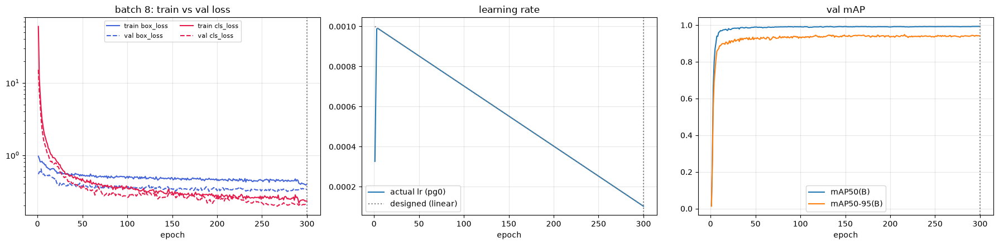

Ultralytics 8.4.183 🚀 Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 7708MiB)


YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5419.3±307.1 MB/s, size: 447.6 KB)


val: Scanning /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/turtle_ninja_split_s0_shape4/labels/val.cache... 50 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 50/50 19.1Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 14% ━╸────────── 1/7 2.8s/it 0.8s<16.9s

...

              puck_box         45         66      0.984      0.948       0.99      0.937


          signal_tower         25         25      0.988          1      0.995       0.96


Speed: 3.3ms preprocess, 45.2ms inference, 0.0ms loss, 1.1ms postprocess per image


Results saved to /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_2_linear_20261023_164149/b12


학습 48.1분, 256 epoch, GPU 최대 7.72 GB | 실제 lr 최고 0.000991 (설계 0.001), 마지막 0.000235 (설계 끝값 0.000100) → ✔


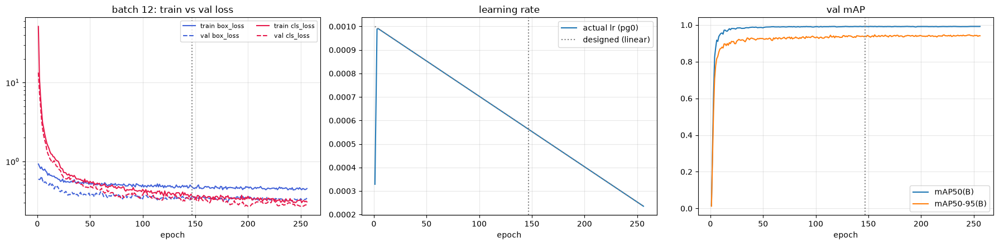

Ultralytics 8.4.183 🚀 Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 7708MiB)


YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5550.0±742.3 MB/s, size: 449.8 KB)


val: Scanning /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/turtle_ninja_split_s0_shape4/labels/val.cache... 50 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 50/50 17.5Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 14% ━╸────────── 1/7 3.2s/it 0.9s<19.0s

...

              puck_box         45         66      0.986      0.909      0.991      0.945


          signal_tower         25         25      0.995          1      0.995      0.961


Speed: 1.5ms preprocess, 7.1ms inference, 0.0ms loss, 2.0ms postprocess per image


Results saved to /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_2_linear_20261023_164149/b16


학습 53.1분, 300 epoch, GPU 최대 7.77 GB | 실제 lr 최고 0.000991 (설계 0.001), 마지막 0.000103 (설계 끝값 0.000100) → ✔


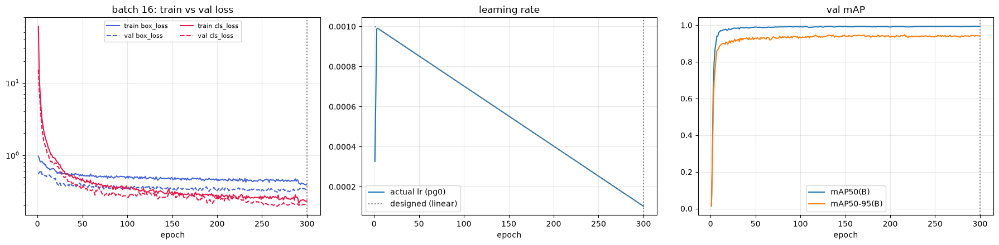

Ultralytics 8.4.183 🚀 Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 7708MiB)


YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5291.6±1239.1 MB/s, size: 449.8 KB)


val: Scanning /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/turtle_ninja_split_s0_shape4/labels/val.cache... 50 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 50/50 17.5Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 14% ━╸────────── 1/7 3.1s/it 0.9s<18.7s

...

              puck_box         45         66      0.984      0.959       0.99      0.949


          signal_tower         25         25      0.979          1      0.995      0.955


Speed: 3.4ms preprocess, 89.4ms inference, 0.0ms loss, 0.4ms postprocess per image


Results saved to /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_2_linear_20261023_164149/b20


학습 52.9분, 300 epoch, GPU 최대 7.48 GB | 실제 lr 최고 0.000991 (설계 0.001), 마지막 0.000103 (설계 끝값 0.000100) → ✔


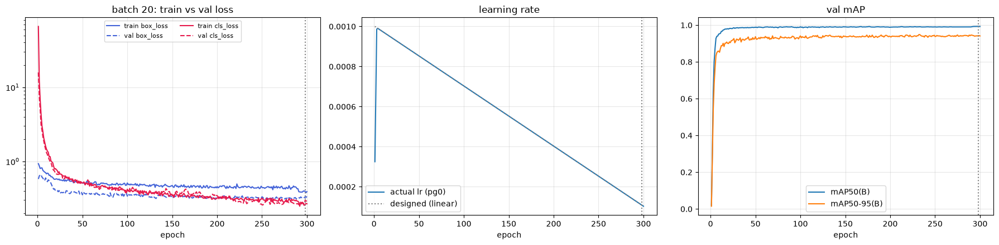

Ultralytics 8.4.183 🚀 Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 7708MiB)


YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 6643.9±1190.3 MB/s, size: 449.8 KB)


val: Scanning /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/turtle_ninja_split_s0_shape4/labels/val.cache... 50 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 50/50 19.1Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 14% ━╸────────── 1/7 3.1s/it 0.9s<18.8s

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 4.2it/s 1.7s

                   all         49         94      0.309      0.172      0.222      0.111


Speed: 4.0ms preprocess, 6.3ms inference, 0.0ms loss, 1.1ms postprocess per image


Results saved to /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_2_linear_20261023_164149/b20/eval_real


batch 20: 합성 test mAP50 0.981 | 실물 mAP50 0.222 | 실물 TP 26 FN 68 FP 28
saved /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_2_linear_20261023_164149/runs.json


In [10]:
runs = {}
for b in BATCHES:
    runs[b] = run_one(b)
    save_json("runs.json", runs)          # batch 하나 끝날 때마다 저장 (중간에 멈춰도 남음)

## 8. batch별 비교 — 표 + 그래프

- 판단 기준은 **실물 mAP50** (합성 점수는 참고). 실물 라벨이 아직 예전 번호면 실물 점수는 믿을 수 없어요.
- `comparison.csv`, `comparison.png`로 저장.

batch | status | epochs_run | best_epoch | best_val_mAP50 | sim_test_mAP50 | real_mAP50 | real_TP | real_FN | real_FP | train_min | peak_gpu_gb | warmup_steps | lr_peak | lr_last
8 | ok | 300 | 300 | 0.9927 | 0.9785 | 0.243 | 27 | 67 | 29 | 55.4 | 6.05 | 150 | 0.000991 | 0.000103
12 | ok | 256 | 147 | 0.9918 | 0.9856 | 0.2974 | 32 | 62 | 21 | 48.1 | 7.72 | 102 | 0.000991 | 0.000235
16 | ok | 300 | 300 | 0.9927 | 0.9785 | 0.243 | 27 | 67 | 29 | 53.1 | 7.77 | 100 | 0.000991 | 0.000103
20 | ok | 300 | 298 | 0.9928 | 0.9807 | 0.2222 | 26 | 68 | 28 | 52.9 | 7.48 | 100 | 0.000991 | 0.000103


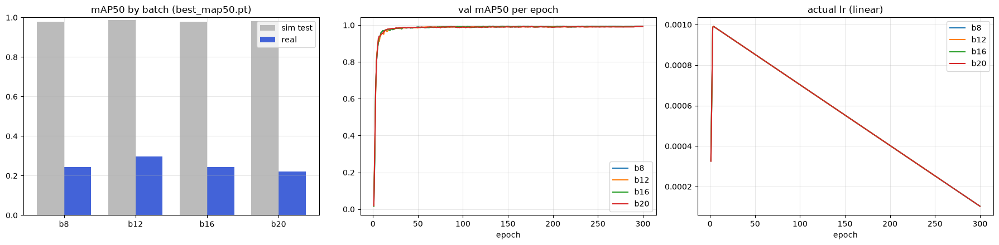

In [11]:
ok = [r for r in runs.values() if r.get("status") == "ok"]
cols = ["batch", "status", "epochs_run", "best_epoch", "best_val_mAP50", "sim_test_mAP50", "real_mAP50",
        "real_TP", "real_FN", "real_FP", "train_min", "peak_gpu_gb", "warmup_steps", "lr_peak", "lr_last"]
table = []
for r in runs.values():
    table.append(dict(batch=r["batch"], status=r["status"], epochs_run=r.get("epochs_run", ""), best_epoch=r.get("best_epoch", ""),
                      best_val_mAP50=r.get("best_val_mAP50", ""), sim_test_mAP50=r.get("sim_test", {}).get("mAP50", ""),
                      real_mAP50=r.get("real", {}).get("mAP50", ""), real_TP=r.get("real_counts", {}).get("TP", ""),
                      real_FN=r.get("real_counts", {}).get("FN", ""), real_FP=r.get("real_counts", {}).get("FP", ""),
                      train_min=r.get("train_min", ""), peak_gpu_gb=r.get("peak_gpu_gb", ""), warmup_steps=r.get("warmup_steps", ""),
                      lr_peak=r.get("lr_peak", ""), lr_last=r.get("lr_last", "")))
with open(EXP_DIR / "comparison.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=cols); w.writeheader(); w.writerows(table)
print(" | ".join(cols))
for t in table:
    print(" | ".join(str(t[c]) for c in cols))

if ok:
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
    xs = np.arange(len(ok)); wdt = 0.38
    ax[0].bar(xs - wdt / 2, [r["sim_test"]["mAP50"] for r in ok], wdt, color="#bbbbbb", label="sim test")
    if all("real" in r for r in ok):
        ax[0].bar(xs + wdt / 2, [r["real"]["mAP50"] for r in ok], wdt, color="#4363d8", label="real")
    ax[0].set_xticks(xs); ax[0].set_xticklabels([f"b{r['batch']}" for r in ok]); ax[0].set_ylim(0, 1)
    ax[0].set_title("mAP50 by batch (best_map50.pt)"); ax[0].legend()
    for r in ok:
        with open(EXP_DIR / f"b{r['batch']}" / "results.csv", encoding="utf-8") as f:
            rr = [{k.strip(): v.strip() for k, v in x.items()} for x in csv.DictReader(f)]
        e = [int(float(x["epoch"])) for x in rr]
        ax[1].plot(e, [float(x["metrics/mAP50(B)"]) for x in rr], label=f"b{r['batch']}")
        ax[2].plot(e, [float(x["lr/pg0"]) for x in rr], label=f"b{r['batch']}")
    ax[1].set_title("val mAP50 per epoch"); ax[1].legend(); ax[1].set_xlabel("epoch")
    ax[2].set_title(f"actual lr ({SCHEDULE})"); ax[2].legend(); ax[2].set_xlabel("epoch")
    for a in ax: a.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(EXP_DIR / "comparison.png", dpi=110); plt.show()

## 9. 요약 — `summary.md` (일지·Notion용)

In [12]:
lines = [f"# {RUN_ID} — batch 비교 ({SCHEDULE})", "",
         f"- 시작 가중치: `{PRETRAINED.name}` (sha256 {sha[:12]}…)",
         f"- 공통 설정: " + ", ".join(f"{k}={v}" for k, v in TRAIN_CFG.items()),
         f"- batch: {BATCHES}",
         f"- 데이터: `{SPLIT_DATASET.name}` — " + ", ".join(f"{s} {stats[s]['images']}장" for s in stats)
         + f" · 실물 {real_stats['images']}장 (라벨 {real_stats['labeled']}장)",
         f"- 환경: torch {env['torch']}, {env['gpu']}, ultralytics {env['ultralytics']}, git {env['git_branch']}@{env['git_commit']}", "",
         "| batch | 상태 | epoch | best epoch | val mAP50 | 합성 test mAP50 | 실물 mAP50 | 실물 TP/FN/FP | 시간(분) | GPU(GB) |",
         "| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |"]
for t in table:
    lines.append(f"| {t['batch']} | {t['status']} | {t['epochs_run']} | {t['best_epoch']} | {t['best_val_mAP50']} | {t['sim_test_mAP50']} | "
                 f"{t['real_mAP50']} | {t['real_TP']}/{t['real_FN']}/{t['real_FP']} | {t['train_min']} | {t['peak_gpu_gb']} |")
if ok and all("real" in r for r in ok):
    top = max(ok, key=lambda r: r["real"]["mAP50"])
    lines += ["", f"실물 mAP50 최고: batch {top['batch']} ({top['real']['mAP50']:.3f}) → `{top['best_path']}`"]
lines += ["", "주의: 합성 점수는 참고용. 실물 라벨이 4클래스 번호(0 qr · 1 puck_cyl · 2 puck_box · 3 signal_tower)인지 확인할 것."]
(EXP_DIR / "summary.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("\n".join(lines))
print(f"\n[{datetime.now():%F %T}] 끝 — {EXP_DIR}")

# experiment_2_linear_20261023_164149 — batch 비교 (linear)

- 시작 가중치: `yolo26n.pt` (sha256 9b09cc8bf347…)
- 공통 설정: epochs=300, patience=100, imgsz=1280, device=0, workers=8, seed=0, deterministic=True, optimizer=SGD, lr0=0.001, lrf=0.1, cos_lr=False, momentum=0.937, warmup_epochs=3, warmup_bias_lr=0.01, warmup_momentum=0.8, close_mosaic=10, hsv_h=0.015, pretrained=True, plots=True, save=True, verbose=True
- batch: [8, 12, 16, 20]
- 데이터: `turtle_ninja_split_s0_shape4` — train 400장, val 50장, test 50장 · 실물 49장 (라벨 49장)
- 환경: torch 2.11.0+cu128, NVIDIA GeForce RTX 5060 Laptop GPU, ultralytics 8.4.183, git feat/camera_calib@e6197f1

| batch | 상태 | epoch | best epoch | val mAP50 | 합성 test mAP50 | 실물 mAP50 | 실물 TP/FN/FP | 시간(분) | GPU(GB) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 8 | ok | 300 | 300 | 0.9927 | 0.9785 | 0.243 | 27/67/29 | 55.4 | 6.05 |
| 12 | ok | 256 | 147 | 0.9918 | 0.9856 | 0.2974 | 32/62/21 | 48.1 | 7.72 |
| 16 | ok | 300 | 300 | 0.9927 | 0.9785 | 0.24